In [1]:
# IMPORT THƯ VIỆN
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)
from scipy.stats import chi2_contingency, chi2
import statsmodels.api as sm

# Đọc dữ liệu
df = pd.read_csv('student_performance_prediction_cleaned.csv')
print("Kích thước tập dữ liệu:", df.shape)
display(df.head())

Kích thước tập dữ liệu: (38000, 6)


,Study Hours per Week,Attendance Rate,Previous Grades,Participation in Extracurricular Activities,Parent Education Level,Passed
0,12.5,69.733333,75.0,Yes,Master,Yes
1,9.3,95.300000,60.6,No,High School,No
2,13.2,73.933333,64.0,No,Associate,Yes
3,17.6,76.800000,62.4,Yes,Bachelor,Yes
4,8.8,89.300000,72.7,No,Master,Yes


In [2]:
# MÃ HÓA DỮ LIỆU
df_encoded = df.copy()

# 1. Mã hóa đầu ra y: Passed ('Yes' -> 1, 'No' -> 0)
df_encoded['y'] = df_encoded['Passed'].map({'Yes': 1, 'No': 0})

# 2. Mã hóa biến Participation in Extracurricular Activities ('Yes' -> 1, 'No' -> 0)
df_encoded['Extracurricular'] = df_encoded['Participation in Extracurricular Activities'].map({'Yes': 1, 'No': 0})

# 3. Tạo ma trận One-Hot cho Parent Education Level
edu_mapping = {
    'High School': 'is_HighSchool',
    'Associate':   'is_Associate',
    'Bachelor':    'is_Bachelor',
    'Master':      'is_Master',
    'Doctorate':   'is_Doctorate'
}

for level_val, col_name in edu_mapping.items():
    df_encoded[col_name] = (df_encoded['Parent Education Level'] == level_val).astype(int)

edu_cols = ['is_HighSchool', 'is_Associate', 'is_Bachelor', 'is_Master', 'is_Doctorate']
print("Ma trận One-Hot của Parent Education Level (5 dòng đầu):")
display(df_encoded[['Parent Education Level'] + edu_cols].head())

# 4. Tập hợp các thuộc tính đầu vào X và nhãn y
num_cols = ['Study Hours per Week', 'Attendance Rate', 'Previous Grades']
feature_cols = num_cols + ['Extracurricular'] + edu_cols

X = df_encoded[feature_cols]
y = df_encoded['y']

# 5. Chia Train/Test -> 80/20 có stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Kích thước tập Train: {X_train.shape} | Tỷ lệ Passed (y=1): {y_train.mean():.4f}")
print(f"Kích thước tập Test : {X_test.shape}  | Tỷ lệ Passed (y=1): {y_test.mean():.4f}")

# 6. Chuẩn hóa 3 biến số liên tục (giữ nguyên các biến nhị phân 0/1) để so sánh trọng số công bằng
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

Ma trận One-Hot của Parent Education Level (5 dòng đầu):


,Parent Education Level,is_HighSchool,is_Associate,is_Bachelor,is_Master,is_Doctorate
0,Master,0,0,0,1,0
1,High School,1,0,0,0,0
2,Associate,0,1,0,0,0
3,Bachelor,0,0,1,0,0
4,Master,0,0,0,1,0


Kích thước tập Train: (30400, 9) | Tỷ lệ Passed (y=1): 0.6648
Kích thước tập Test : (7600, 9)  | Tỷ lệ Passed (y=1): 0.6649


In [3]:
# HUẤN LUYỆN LOGISTIC & ĐÁNH GIÁ
# 1. Mô hình Đầy đủ
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

y_pred = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

# 2. Mô hình Rút gọn (Không có Parent Education) để đối chiếu độ cải thiện
cols_no_edu = num_cols + ['Extracurricular']
log_model_no_edu = LogisticRegression(max_iter=1000, random_state=42)
log_model_no_edu.fit(X_train_scaled[cols_no_edu], y_train)
y_pred_no_edu = log_model_no_edu.predict(X_test_scaled[cols_no_edu])
y_prob_no_edu = log_model_no_edu.predict_proba(X_test_scaled[cols_no_edu])[:, 1]

print("================ KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ================")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f} (Không có Parent Edu: {accuracy_score(y_test, y_pred_no_edu):.4f})")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC   : {roc_auc_score(y_test, y_prob):.4f} (Không có Parent Edu: {roc_auc_score(y_test, y_prob_no_edu):.4f})")
print("\nBáo cáo phân loại chi tiết (Classification Report):")
print(classification_report(y_test, y_pred, target_names=['Failed (0)', 'Passed (1)']))

================ KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ================
Accuracy  : 0.7847 (Không có Parent Edu: 0.7712)
Precision : 0.8132
Recall    : 0.8779
F1-Score  : 0.8443
ROC-AUC   : 0.8431 (Không có Parent Edu: 0.8276)

Báo cáo phân loại chi tiết (Classification Report):
              precision    recall  f1-score   support

  Failed (0)       0.71      0.60      0.65      2547
  Passed (1)       0.81      0.88      0.84      5053

    accuracy                           0.78      7600
   macro avg       0.76      0.74      0.75      7600
weighted avg       0.78      0.78      0.78      7600



In [4]:
# ĐỘ ẢNH HƯỞNG CỦA PARENT EDUCATION
# 1. Thống kê tỷ lệ đỗ theo từng bậc học vấn & Kiểm định Chi-Square
ct_counts = pd.crosstab(df['Parent Education Level'], df['Passed'])
ct_pct = pd.crosstab(df['Parent Education Level'], df['Passed'], normalize='index') * 100
chi2_stat, p_val_chi2, dof, _ = chi2_contingency(ct_counts)

print("1. Tỷ lệ Đỗ/Trượt (%) theo trình độ học vấn phụ huynh:")
display(ct_pct.loc[['High School', 'Associate', 'Bachelor', 'Master', 'Doctorate']].round(2))
print(f"=> Kiểm định Chi-Square: chi2 = {chi2_stat:.4f}, p-value = {p_val_chi2:.4e}\n")

# 2. Bảng trọng số Beta và Odds Ratio từ mô hình Logistic Regression (Scikit-learn)
coef_summary = pd.DataFrame({
    'Thuộc tính (Feature)': feature_cols,
    'Trọng số Beta (Scaled)': log_model.coef_[0],
    'Odds Ratio (exp(Beta))': np.exp(log_model.coef_[0])
})
# Tính thêm chênh lệch so với mốc is_HighSchool cho 5 biến học vấn
base_hs_beta = log_model.coef_[0][feature_cols.index('is_HighSchool')]
coef_summary['Delta Beta (vs HighSchool)'] = [
    (b - base_hs_beta) if f in edu_cols else np.nan
    for f, b in zip(feature_cols, log_model.coef_[0])
]
coef_summary['Odds Ratio (vs HighSchool)'] = np.exp(coef_summary['Delta Beta (vs HighSchool)'])

print("2. Bảng trọng số ảnh hưởng của các thuộc tính trong Logistic Regression:")
display(coef_summary.round(4))

# 3. Kiểm định p-value của từng bậc học vấn (Statsmodels Logit, mốc tham chiếu = is_HighSchool)
X_train_sm = sm.add_constant(X_train_scaled.drop(columns=['is_HighSchool']))
logit_sm = sm.Logit(y_train, X_train_sm).fit(disp=False)
print("3. Kiểm định ý nghĩa thống kê (Wald Test p-value) với mốc tham chiếu is_HighSchool:")
print(logit_sm.summary())

1. Tỷ lệ Đỗ/Trượt (%) theo trình độ học vấn phụ huynh:


Passed,No,Yes
Parent Education Level,,
High School,45.57,54.43
Associate,39.39,60.61
Bachelor,33.34,66.66
Master,27.39,72.61
Doctorate,21.77,78.23


=> Kiểm định Chi-Square: chi2 = 1153.6241, p-value = 1.8009e-248

2. Bảng trọng số ảnh hưởng của các thuộc tính trong Logistic Regression:


,Thuộc tính (Feature),Trọng số Beta (Scaled),Odds Ratio (exp(Beta)),Delta Beta (vs HighSchool),Odds Ratio (vs HighSchool)
0,Study Hours per Week,0.7227,2.0601,NaN,NaN
1,Attendance Rate,0.7804,2.1824,NaN,NaN
2,Previous Grades,1.1461,3.1459,NaN,NaN
3,Extracurricular,0.9913,2.6946,NaN,NaN
4,is_HighSchool,-0.6781,0.5076,0.0000,1.0000
5,is_Associate,-0.3119,0.7321,0.3662,1.4422
6,is_Bachelor,0.0740,1.0768,0.7520,2.1213
7,is_Master,0.4799,1.6159,1.1580,3.1834
8,is_Doctorate,0.8998,2.4592,1.5779,4.8447


3. Kiểm định ý nghĩa thống kê (Wald Test p-value) với mốc tham chiếu is_HighSchool:
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                30400
Model:                          Logit   Df Residuals:                    30391
Method:                           MLE   Df Model:                            8
Date:                Fri, 16 Oct 2026   Pseudo R-squ.:                  0.2873
Time:                        12:16:32   Log-Likelihood:                -13819.
converged:                       True   LL-Null:                       -19388.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   -0.2127      0.035     -6.082      0.000      -0.281      -0.144
Study Hours per W

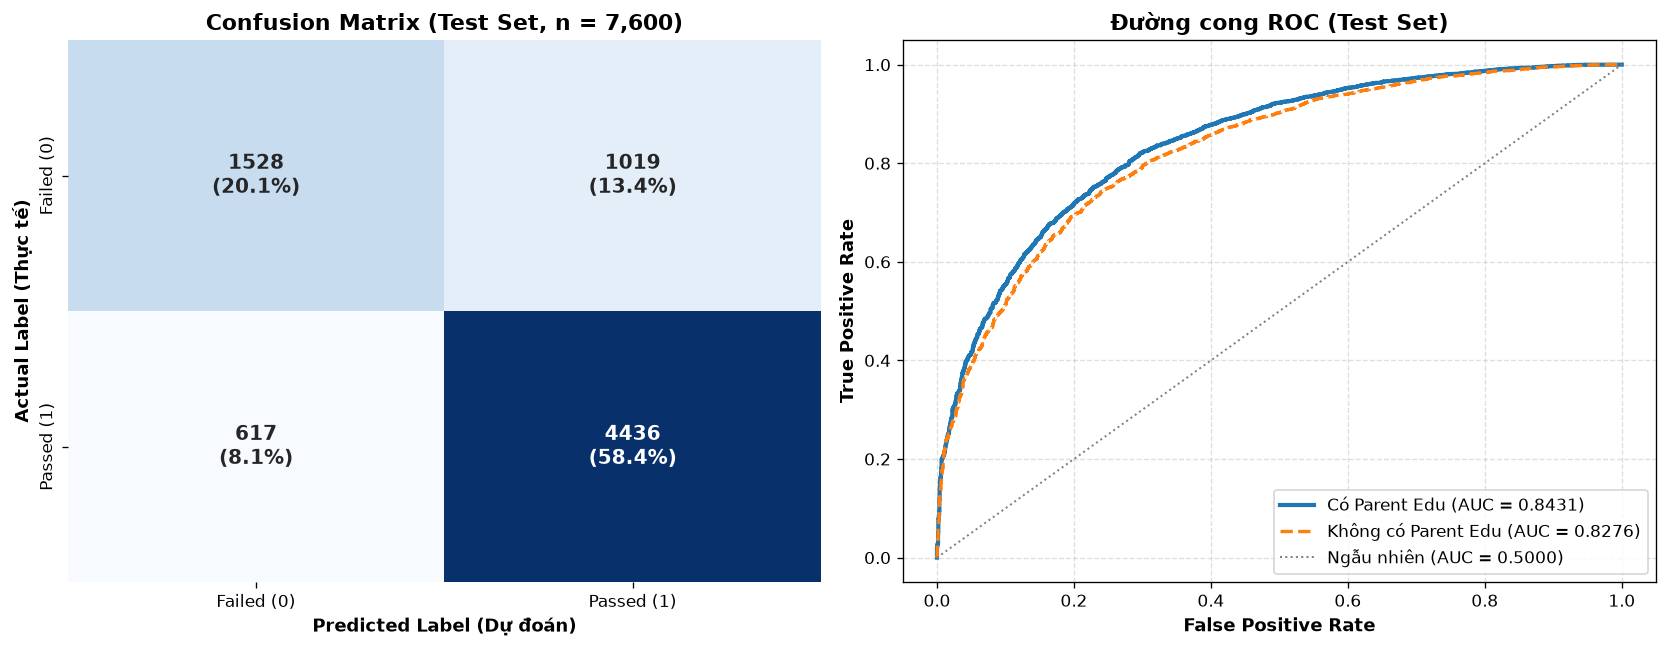

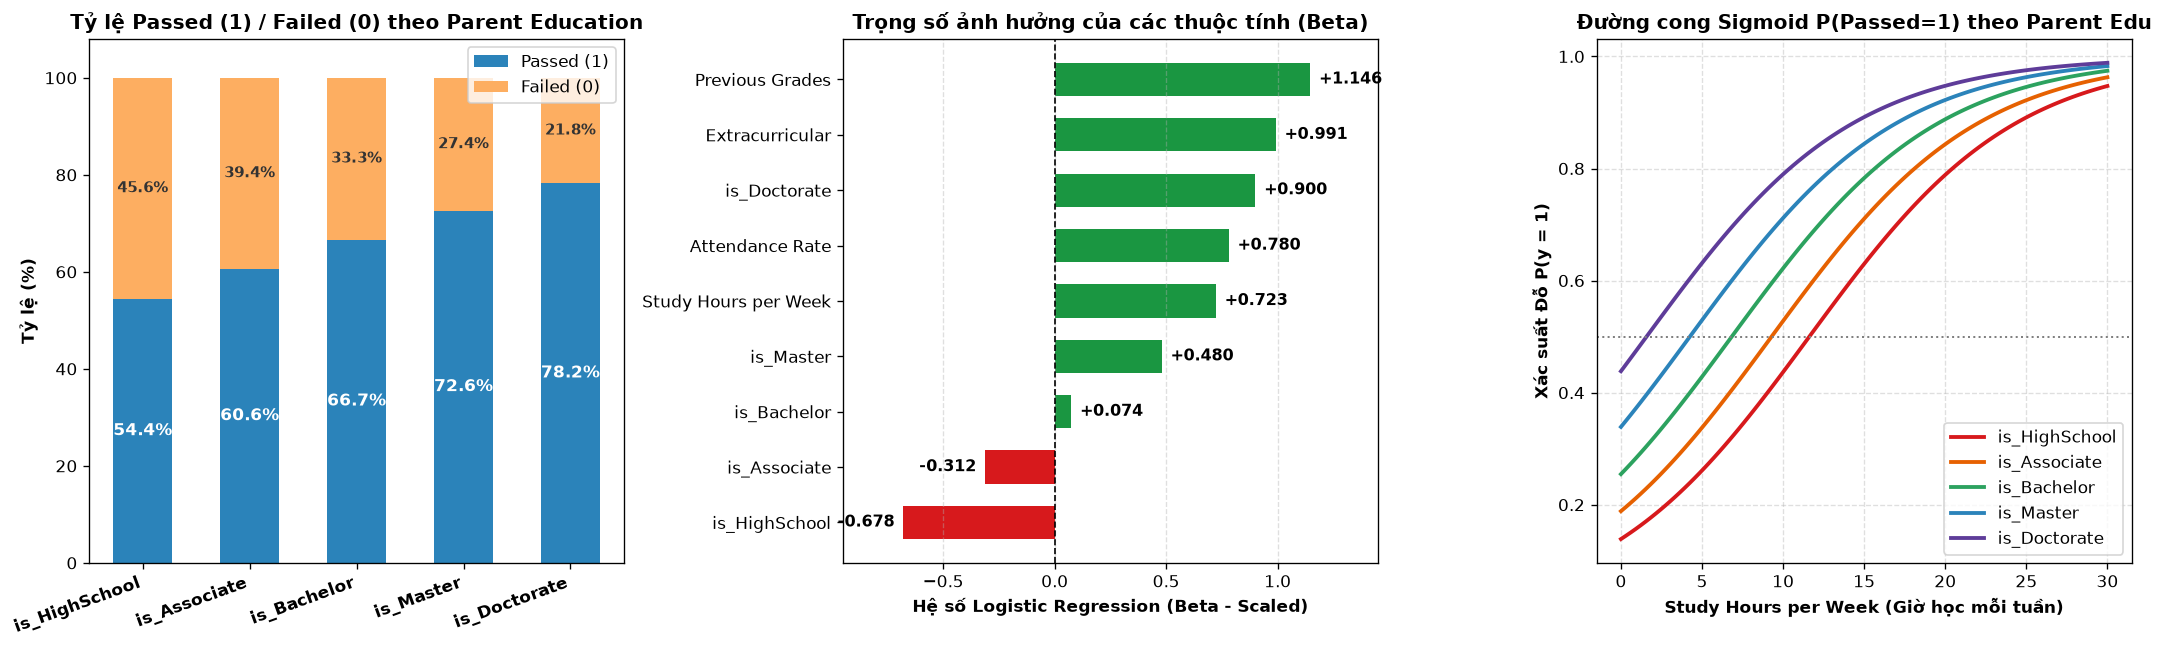

In [5]:
# TRỰC QUAN HÓA ĐỒ THỊ
# --- CONFUSION MATRIX & ĐƯỜNG CONG ROC ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=120)

cm = confusion_matrix(y_test, y_pred)
cm_pct = cm / cm.sum() * 100
annot_labels = np.array([[f"{val}\n({pct:.1f}%)" for val, pct in zip(row_v, row_p)]
                         for row_v, row_p in zip(cm, cm_pct)])

sns.heatmap(cm, annot=annot_labels, fmt='', cmap='Blues', cbar=False, ax=axes[0],
            xticklabels=['Failed (0)', 'Passed (1)'],
            yticklabels=['Failed (0)', 'Passed (1)'],
            annot_kws={'size': 12, 'weight': 'bold'})
axes[0].set_title('Confusion Matrix (Test Set, n = 7,600)', fontsize=13, weight='bold')
axes[0].set_xlabel('Predicted Label (Dự đoán)', fontsize=11, weight='bold')
axes[0].set_ylabel('Actual Label (Thực tế)', fontsize=11, weight='bold')

fpr, tpr, _ = roc_curve(y_test, y_prob)
fpr_no, tpr_no, _ = roc_curve(y_test, y_prob_no_edu)
axes[1].plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'Có Parent Edu (AUC = {roc_auc_score(y_test, y_prob):.4f})')
axes[1].plot(fpr_no, tpr_no, color='#ff7f0e', lw=2, linestyle='--', label=f'Không có Parent Edu (AUC = {roc_auc_score(y_test, y_prob_no_edu):.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', lw=1.2, linestyle=':', label='Ngẫu nhiên (AUC = 0.5000)')
axes[1].set_title('Đường cong ROC (Test Set)', fontsize=13, weight='bold')
axes[1].set_xlabel('False Positive Rate', fontsize=11, weight='bold')
axes[1].set_ylabel('True Positive Rate', fontsize=11, weight='bold')
axes[1].legend(loc='lower right')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

# --- PHÂN TÍCH ẢNH HƯỞNG CỦA PARENT EDUCATION LEVEL ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=120)

# Biểu đồ 1: Tỷ lệ Passed/Failed theo bậc học vấn
pass_rates = [df_encoded[df_encoded[col] == 1]['y'].mean() * 100 for col in edu_cols]
fail_rates = [100 - r for r in pass_rates]
x_pos = np.arange(len(edu_cols))

axes[0].bar(x_pos, pass_rates, color='#2b83ba', width=0.55, label='Passed (1)')
axes[0].bar(x_pos, fail_rates, bottom=pass_rates, color='#fdae61', width=0.55, label='Failed (0)')
for i, r in enumerate(pass_rates):
    axes[0].text(i, r / 2, f"{r:.1f}%", ha='center', va='center', color='white', weight='bold')
    axes[0].text(i, r + (100 - r) / 2, f"{100-r:.1f}%", ha='center', va='center', color='#333333', weight='bold', fontsize=9)

axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(edu_cols, rotation=20, ha='right', weight='bold')
axes[0].set_ylabel('Tỷ lệ (%)', weight='bold')
axes[0].set_ylim(0, 108)
axes[0].set_title('Tỷ lệ Passed (1) / Failed (0) theo Parent Education', weight='bold')
axes[0].legend(loc='upper right')

# Biểu đồ 2: Trọng số Beta của các thuộc tính
coef_plot_df = coef_summary.sort_values(by='Trọng số Beta (Scaled)', ascending=True)
colors = ['#d7191c' if c < 0 else '#1a9641' for c in coef_plot_df['Trọng số Beta (Scaled)']]
bars = axes[1].barh(coef_plot_df['Thuộc tính (Feature)'], coef_plot_df['Trọng số Beta (Scaled)'], color=colors, height=0.6)
axes[1].axvline(0, color='black', lw=1, linestyle='--')
for bar in bars:
    w = bar.get_width()
    axes[1].text(w + (0.04 if w >= 0 else -0.04), bar.get_y() + bar.get_height()/2,
                 f"{w:+.3f}", va='center', ha=('left' if w >= 0 else 'right'), weight='bold', fontsize=9.5)
axes[1].set_xlim(-0.95, 1.45)
axes[1].set_xlabel('Hệ số Logistic Regression (Beta - Scaled)', weight='bold')
axes[1].set_title('Trọng số ảnh hưởng của các thuộc tính (Beta)', weight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

# Biểu đồ 3: Đường cong Sigmoid dự đoán xác suất đỗ theo Giờ học & Học vấn phụ huynh
study_hours_range = np.linspace(0, 30, 100)
study_hours_scaled = (study_hours_range - X_train['Study Hours per Week'].mean()) / X_train['Study Hours per Week'].std()
line_colors = ['#d7191c', '#e66101', '#2ca25f', '#2b83ba', '#5e3c99']

for idx, col in enumerate(edu_cols):
    X_sim = pd.DataFrame(0.0, index=range(100), columns=feature_cols)
    X_sim['Study Hours per Week'] = study_hours_scaled
    X_sim[col] = 1.0
    probs = log_model.predict_proba(X_sim)[:, 1]
    axes[2].plot(study_hours_range, probs, lw=2.3, color=line_colors[idx], label=col)

axes[2].axhline(0.5, color='gray', linestyle=':', lw=1.2)
axes[2].set_xlabel('Study Hours per Week (Giờ học mỗi tuần)', weight='bold')
axes[2].set_ylabel('Xác suất Đỗ P(y = 1)', weight='bold')
axes[2].set_title('Đường cong Sigmoid P(Passed=1) theo Parent Edu', weight='bold')
axes[2].legend(loc='lower right')
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()